In [1]:
"""
Callset benchmarking and comparison.
"""

import copy
import importlib
import re
import pickle
import warnings
from pathlib import Path
from collections import defaultdict
import time

import numpy as np
import pandas as pd
import matplotlib as mpl
import pyranges as pr
import pysam
import seaborn as sns
import shap
from scipy.spatial import cKDTree
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import os
from typing import Union, Tuple, Optional, List, Any, Literal, Dict


workdir = Path("/vast/ai_projects/Papenfuss_SVEnsemble2")
os.chdir(workdir)
os.getcwd()

import svensemble.vcfparse as vcfp # noqa: E402 (flake8)
import svensemble.breakends as bnds
import svensemble.breakpoints as bps
import svensemble.matched_breakpoints as mbps
import svensemble.events as evts
import svensemble.caller_specific as caller_specific
import svensemble.benchmark as benchmark
import svensemble._caller_params as caller_params
import svensemble._sample_params as sample_params
import svensemble.chunk_match as chunk_match
import svensemble.matched_breakpoints as matchedbps
import svensemble.utils as sv_utils
import svensemble.importances as importances

importlib.reload(vcfp)
importlib.reload(bnds)
importlib.reload(bps)
importlib.reload(mbps)
importlib.reload(evts)
importlib.reload(caller_specific)
importlib.reload(benchmark)
importlib.reload(caller_params)
importlib.reload(sample_params)
importlib.reload(chunk_match)
importlib.reload(matchedbps)
importlib.reload(sv_utils)

pd.set_option('display.max_columns', None)


In [2]:
ground_truth_sample_name = 'gnomad'
sample_train = 'NA12878'
sample_pred = 'HG002'
model_name = f'unbiased_cross_train_{sample_train}'
training_set_name = 'delly+manta_diploid'


training_set_blacklist = ['manta_candidate', 'svensemble2_manta_candidate', 'svensemble2_gridss+manta_candidate+delly', 'svensemble2_gridss+manta_candidate', 'svensemble2_delly+manta_candidate', 'svensemble2_gridss+delly']


In [3]:
ground_truth_sample_config = sv_utils.create_config_dict(ground_truth_sample_name, is_ground_truth=True)[ground_truth_sample_name]
sample_train_config = sv_utils.create_config_dict(sample_train, val_set='use_name')[sample_train]
sample_pred_config = sv_utils.create_config_dict(sample_pred, val_set='use_name')[sample_pred]

model_train_path = workdir / f'data/{sample_train}/sv_calling/svensemble2/{sample_train}.{sample_train_config["model"]["model_pkl_suffix"]}.model_dict.pkl'
model_train = pickle.load(open(model_train_path, 'rb'))

Adding custom columns to the config dict for sample NA12878
Custom columns: []
Adding custom columns to the config dict for sample HG002
Custom columns: []


In [4]:

joint_bp_pred_path = (
        sample_pred_config['sample_dir'] /
        'sv_calling' /
        'svensemble2' /
        f'{sample_pred}.matched_bps.{training_set_name}.{sample_pred_config["model"]["bps_suffix"]}.csv'
    )
joint_bp_pred = pd.read_csv(joint_bp_pred_path, low_memory=False)
training_set_df = mbps.preprocess_matchedbps_for_pu(
    joint_bp_pred,
    sample_pred_config,
    ground_truth_sample_config['callsets'][list(ground_truth_sample_config['callsets'].keys())[0]]['source'],
    training_set_name,
    verbose=True
)
X, y = mbps.get_X_y_from_training_df(
        training_set_df,
        match_col='ref_match'
    )

/vast/ai_projects/Papenfuss_SVEnsemble2/svensemble/matched_breakpoints.py:279: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/vast/ai_projects/Papenfuss_SVEnsemble2/svensemble/matched_breakpoints.py:279: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


Dropping 3 constant columns: ['delly_INFO_IMPRECISE', 'delly_INFO_SVMETHOD', 'manta_diploid_INFO_IMPRECISE']


In [5]:
features_train = model_train[training_set_name]['RF_fit'].feature_names_in_
features_pred = X.columns

if len(features_train[~pd.Series(features_train).isin(features_pred)]) > 0:
    print(f"Features in training set but not in prediction set: {features_train[~pd.Series(features_train).isin(features_pred)]}")
    X.loc[:, features_train[~pd.Series(features_train).isin(features_pred)]] = 0
    # Reorder columns to match training set columns
    X = X[features_train]


Features in training set but not in prediction set: ['delly_SAMPLE_GT_(None, None)']


In [6]:
cross_model_y = model_train[training_set_name]['RF_fit'].predict_proba(X)
cross_model_y = pd.DataFrame(cross_model_y, index=training_set_df.index)
cross_model_y = cross_model_y.reset_index(drop=False)
cross_model_y.drop(columns=[0, 'gnomad_INFO_EVENT'], inplace=True)
cross_model_y.rename(columns={1: f'{training_set_name}_{model_name}_pred'}, inplace=True)

joint_bp_pred = joint_bp_pred.drop(columns=joint_bp_pred.columns[joint_bp_pred.columns.str.contains('gnomad')])

cross_model_ensemble_bps = mbps.get_svensemble2_calls(
    joint_bp_pred,
    cross_model_y
)

In [7]:
cross_model_ensemble_bps.loc[:, "INFO_SVLEN"] = bps.get_sv_sizes(cross_model_ensemble_bps, 'svensemble2')
cross_model_ensemble_bps.loc[:, "INFO_SVTYPE"] = bps.annotate_svtypes(cross_model_ensemble_bps, 'svensemble2')
cross_model_ensemble_bps = cross_model_ensemble_bps[(cross_model_ensemble_bps['INFO_SVLEN'] >= 50) & (cross_model_ensemble_bps['INFO_SVTYPE'].isin(['DEL', 'INS']))]

In [8]:
val_set = pd.read_csv(sample_pred_config['val_set']['path'])
val_set = val_set[val_set['INFO_SVLEN'] >= 50]

In [9]:
val_df_cross = benchmark.validate_svensemble2_predictions(
        svensemble2_bps=cross_model_ensemble_bps,
        val_set=val_set,
        sample_config=sample_pred_config,
        training_set_name=training_set_name,
        model_name=model_name,
        val_match_margin=1000,
        additional_cols=None,
        verbose=True
    )

Number of chunks: 21361


/vast/ai_projects/Papenfuss_SVEnsemble2/svensemble/benchmark.py:574: UserWarning: Legend does not support handles for Text instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend(loc='center left', bbox_transform=ax.transAxes, bbox_to_anchor=(1, 0.5), frameon=False)
/tmp/ipykernel_2818440/592496440.py:25: UserWarning: Legend does not support handles for Text instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  legend = plt.legend(loc='center left', bbox_transform=ax.transAxes, bbox_to_anchor=(1, 0.5), frameon=False)


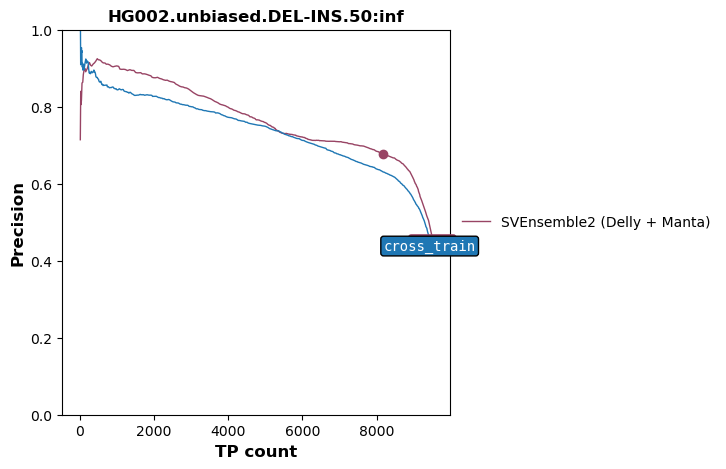

In [ ]:
model_name = 'unbiased'
svlens = (50, np.inf)
svtype_str = 'DEL-INS'

val_dict_path = Path(f'/home/users/allstaff/shikov.v/projects/Papenfuss_SVEnsemble2/data/{sample_pred}/sv_calling/svensemble2/{sample_pred}.{model_name}.{svtype_str}.{svlens[0]}:{svlens[1]}.val_dict.pkl')
if not val_dict_path.exists():
    print(f'{val_dict_path} does not exist')

val_dict = pickle.load(open(val_dict_path, 'rb'))

# Filter GRIDSS calls by FILTER_PASS
try:
    val_dict['gridss_H'] = val_dict['gridss'][val_dict['gridss']['FILTER_PASS_bnd1'].astype(bool) & val_dict['gridss']['FILTER_PASS_bnd2'].astype(bool)]
except KeyError:
    print(f'{sample_pred} does not have FILTER_PASS_bnd1 or FILTER_PASS_bnd2 columns')

# Drop callsets and svensemble2 calls with names in the blacklist
# val_dict = {k: v for k, v in val_dict.items() if k not in training_set_blacklist}
val_dict = {k: v for k, v in val_dict.items() if k == f'svensemble2_{training_set_name}'}
val_dict.update({
    'cross_train': val_df_cross
})
fig, ax = plt.subplots(figsize=(5, 5))
benchmark.plot_precision_recall_curves(val_dict, title=f'{sample_pred}.{model_name}.{svtype_str}.{svlens[0]}:{svlens[1]}', ax=ax, svensemble2_cutoff=0.15)
legend = plt.legend(loc='center left', bbox_transform=ax.transAxes, bbox_to_anchor=(1, 0.5), frameon=False)
out_dir = Path(f'/home/users/allstaff/shikov.v/projects/Papenfuss_SVEnsemble2/data/{sample_pred}/sv_calling/svensemble2/figs/prc')
if not out_dir.exists():
    os.makedirs(out_dir)
fig.savefig(
    out_dir / f'prc.{sample_pred}.{model_name}.{svtype_str}.{svlens[0]}:{svlens[1]}.CROSS_{sample_train}:{training_set_name}.png',
    dpi=300,
    bbox_inches='tight',
    pad_inches=0.1
)


In [ ]:
val_dict

In [148]:
val_dict.keys()

dict_keys(['manta_diploid', 'gridss', 'manta_candidate', 'delly', 'svensemble2_gridss', 'svensemble2_manta_candidate', 'svensemble2_manta_diploid', 'svensemble2_delly', 'svensemble2_gridss+manta_candidate', 'svensemble2_gridss+manta_diploid', 'svensemble2_gridss+delly', 'svensemble2_gridss+manta_candidate+delly', 'svensemble2_gridss+manta_diploid+delly', 'svensemble2_delly+manta_candidate', 'svensemble2_delly+manta_diploid'])

/vast/ai_projects/Papenfuss_SVEnsemble2/svensemble/benchmark.py:574: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='center left', bbox_transform=ax.transAxes, bbox_to_anchor=(1, 0.5), frameon=False)


<Axes: xlabel='TP count', ylabel='Precision'>

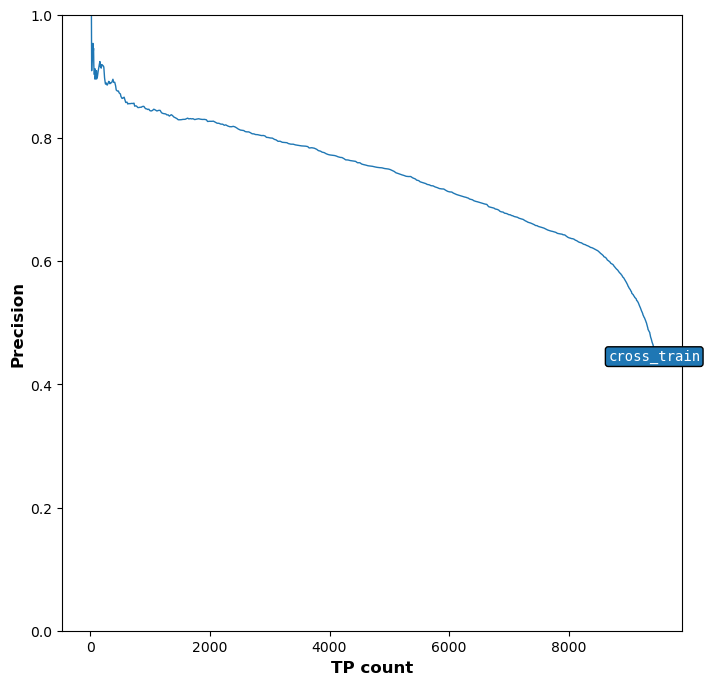

In [ ]:
benchmark.plot_precision_recall_curves(
    {'cross_train': val_df_cross}
)